# Benchmark visualisations (ASQ-PHI text track)

Plots of the CSV files written by `asq_process.ipynb` (Section 8). Run that notebook first. Figures are saved to `results/figures/` for the report.

Set `MODEL_TAG` to the model whose results you want to plot.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

MODEL_TAG   = "qwen3-0.6b"
RESULTS_DIR = Path("results")
FIG_DIR     = RESULTS_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

overall      = pd.read_csv(RESULTS_DIR / f"{MODEL_TAG}_overall.csv")
per_category = pd.read_csv(RESULTS_DIR / f"{MODEL_TAG}_per_category.csv")
per_asq_type = pd.read_csv(RESULTS_DIR / f"{MODEL_TAG}_per_asq_type.csv")
query_level  = pd.read_csv(RESULTS_DIR / f"{MODEL_TAG}_query_level.csv")

# one fixed colour per condition, so a condition looks the same in every figure
COLORS = {"zeroshot": "#2a78d6", "fewshot": "#eb6834", "presidio": "#1baf7a", "fewshot_think": "#eda100"}
NAMES  = {"zeroshot": "Qwen zero-shot", "fewshot": "Qwen few-shot",
          "presidio": "Presidio (baseline)", "fewshot_think": "Qwen few-shot + thinking"}
ORDER  = [c for c in COLORS if c in set(overall.condition)]
print("conditions:", ORDER)

SURFACE, TEXT, TEXT2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": TEXT2, "text.color": TEXT,
    "xtick.color": TEXT2, "ytick.color": TEXT2, "axes.grid": True, "axes.axisbelow": True,
    "grid.color": GRID, "grid.linewidth": 0.8, "axes.spines.top": False, "axes.spines.right": False,
    "axes.spines.left": False, "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "legend.frameon": False,
})

def grouped_bars(ax, frame, x_col, x_order, value_col, x_labels=None, horizontal=False):
    """one bar per condition and x value; values are written on the bars"""
    n = len(ORDER)
    width = 0.8 / n
    for k, c in enumerate(ORDER):
        sub = frame[frame.condition == c].set_index(x_col).reindex(x_order)
        pos = [i + (k - (n - 1) / 2) * width for i in range(len(x_order))]
        draw = ax.barh if horizontal else ax.bar
        bars = draw(pos, sub[value_col], width, color=COLORS[c], label=NAMES[c],
                    edgecolor=SURFACE, linewidth=1.5)
        ax.bar_label(bars, fmt="%.2f", fontsize=7, color=TEXT2, padding=2)
    ticks = x_labels or x_order
    if horizontal:
        ax.set_yticks(range(len(x_order)), ticks)
        ax.grid(axis="y", visible=False)
        ax.set_xlim(0, 1.1)
    else:
        ax.set_xticks(range(len(x_order)), ticks)
        ax.grid(axis="x", visible=False)
        ax.set_ylim(0, 1.1)

def save(fig, name):
    path = FIG_DIR / f"{MODEL_TAG}_{name}.png"
    fig.savefig(path, dpi=200, bbox_inches="tight")
    print("saved", path)

Matplotlib is building the font cache; this may take a moment.


conditions: ['zeroshot', 'fewshot', 'presidio']


## 1. Overall precision, recall and F1

Micro-averaged over all spans, for the three matching modes (`strict`: same boundaries and label; `overlap`: overlapping characters and same label; `any`: overlapping characters, label ignored).

saved results/figures/qwen3-0.6b_overall.png


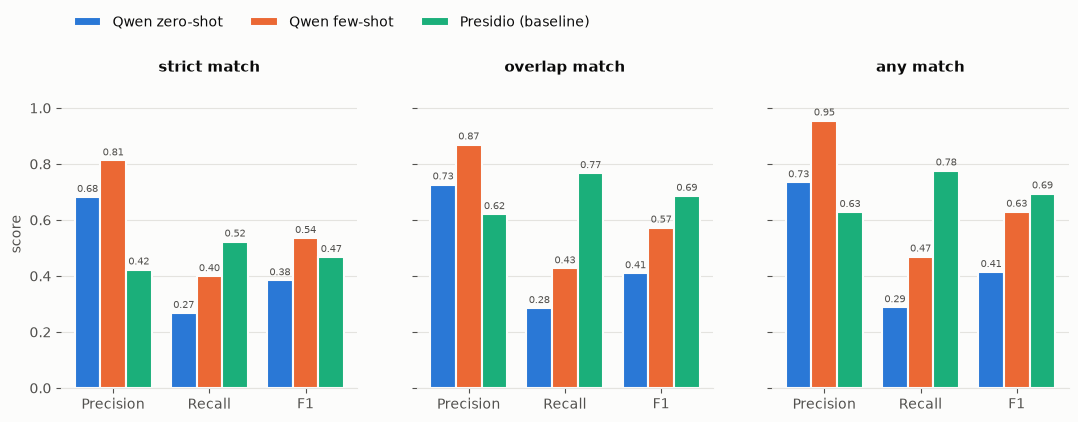

In [2]:
metrics = ["precision", "recall", "f1"]
long = overall.melt(id_vars=["condition", "mode"], value_vars=metrics, var_name="metric")

fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
for ax, mode in zip(axes, ["strict", "overlap", "any"]):
    grouped_bars(ax, long[long["mode"] == mode], "metric", metrics, "value", ["Precision", "Recall", "F1"])
    ax.set_title(f"{mode} match")
axes[0].set_ylabel("score")
axes[0].legend(loc="upper left", bbox_to_anchor=(0, 1.25), ncol=len(ORDER))
save(fig, "overall")
plt.show()

## 2. Results per shared PHI category

`overlap` mode. Recall uses the gold label, precision the predicted label. `n` is the number of gold spans.

saved results/figures/qwen3-0.6b_per_category.png


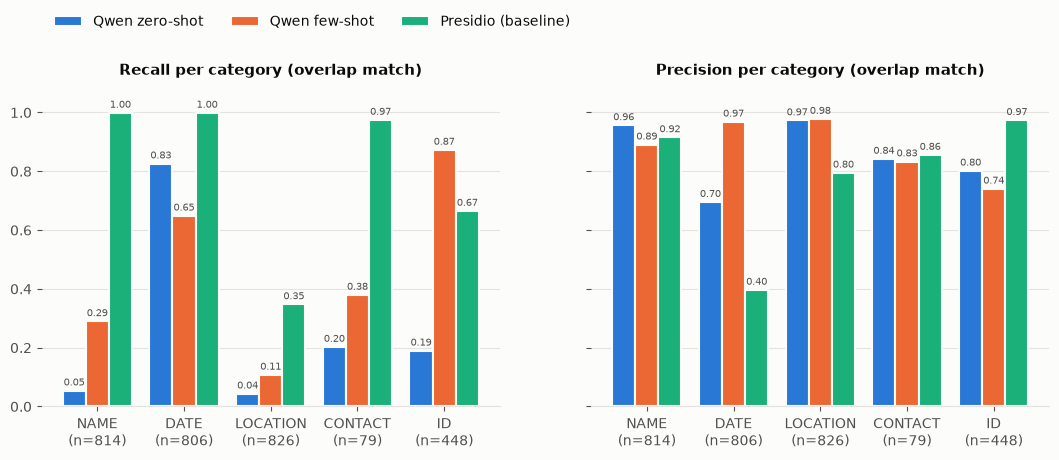

In [3]:
MODE = "overlap"
labels = ["NAME", "DATE", "LOCATION", "CONTACT", "ID"]
cat = per_category[per_category["mode"] == MODE]
n_gold = cat.drop_duplicates("label").set_index("label")["n_gold"]
ticks = [f"{l}\n(n={n_gold[l]})" for l in labels]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
for ax, metric in zip(axes, ["recall", "precision"]):
    grouped_bars(ax, cat, "label", labels, metric, ticks)
    ax.set_title(f"{metric.capitalize()} per category ({MODE} match)")
axes[0].legend(loc="upper left", bbox_to_anchor=(0, 1.25), ncol=len(ORDER))
save(fig, "per_category")
plt.show()

## 3. Recall per original ASQ-PHI type

`any` mode (would this PHI have been redacted?). Sorted by number of gold spans; types with very few examples are anecdotal.

saved results/figures/qwen3-0.6b_per_asq_type.png


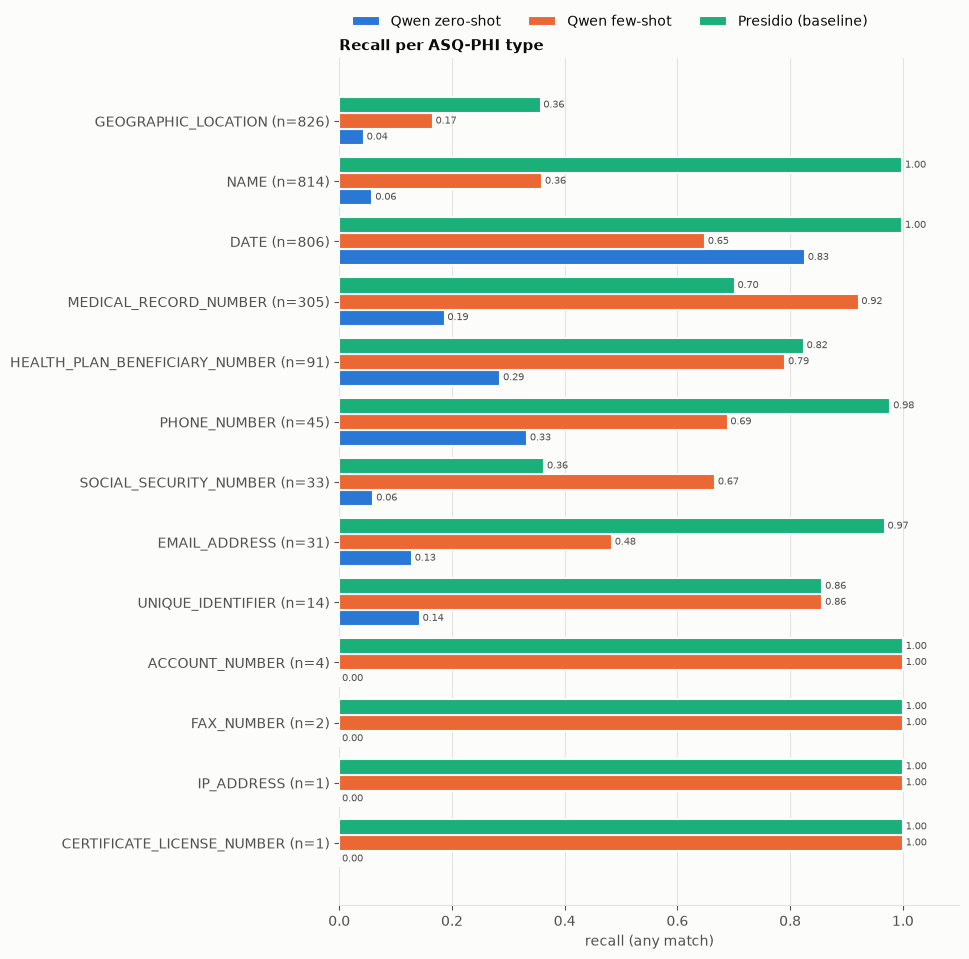

In [4]:
n_type = per_asq_type.drop_duplicates("asq_type").set_index("asq_type")["n"].sort_values()
types = list(n_type.index)

fig, ax = plt.subplots(figsize=(8, 11))
grouped_bars(ax, per_asq_type, "asq_type", types, "recall_any",
             [f"{t} (n={n_type[t]})" for t in types], horizontal=True)
ax.set_xlabel("recall (any match)")
ax.set_title("Recall per ASQ-PHI type", loc="left")
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.02), ncol=len(ORDER))
save(fig, "per_asq_type")
plt.show()

## 4. Query-level privacy metrics

- **leak-free rate** (higher is better): share of queries with PHI where every gold span was caught.
- **false alarm rate** (lower is better): share of queries without PHI where something was still predicted.

saved results/figures/qwen3-0.6b_query_level.png


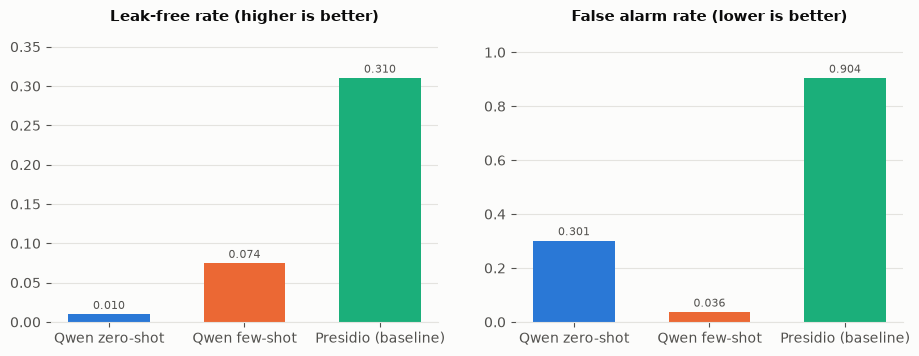

In [5]:
q = query_level.set_index("condition").reindex(ORDER)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, col, title in zip(axes, ["leak_free_rate", "false_alarm_rate"],
                          ["Leak-free rate (higher is better)", "False alarm rate (lower is better)"]):
    bars = ax.bar([NAMES[c] for c in ORDER], q[col], color=[COLORS[c] for c in ORDER], width=0.6)
    ax.bar_label(bars, fmt="%.3f", fontsize=8, color=TEXT2, padding=2)
    ax.set_ylim(0, max(1e-9, q[col].max()) * 1.2)
    ax.grid(axis="x", visible=False)
    ax.set_title(title)
save(fig, "query_level")
plt.show()